# Analisis Hubungan Tingkat Inflasi dan Skor Kebahagiaan Antarnegara Periode 2015–2023 Menggunakan Regresi Linear

## Proyek UTS Data Science — Kerangka CRISP-DM

**Disusun oleh:**
- Nama anggota 1: Aulia Rahma Habibah 123240190
- Nama anggota 2: Sabrina Alya Fadhillah 123240196
- Nama anggota 3: Bisma Putra Pangestu 123240217
- Nama anggota 4: Muhammad Syawal Azzami 123240224

**Program Studi Informatika — UPN “Veteran” Yogyakarta**

Notebook ini disusun dengan alur **Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment**. Struktur penjelasan mengikuti gaya .

> **Batasan penting:** hasil korelasi dan regresi menunjukkan asosiasi statistik, bukan bukti sebab-akibat. Lengkapi sumber, URL, lisensi, dan tanggal akses dataset berdasarkan tempat file asli diperoleh; informasi tersebut tidak dapat dipastikan hanya dari nama CSV.

## Daftar Isi

1. [Business Understanding](#1.-Business-Understanding)
2. [Data Understanding](#2.-Data-Understanding)
3. [Data Preparation](#3.-Data-Preparation)
4. [Modeling](#4.-Modeling)
5. [Evaluation](#5.-Evaluation)
6. [Deployment](#6.-Deployment)
7. [Kesimpulan dan pekerjaan lanjutan](#Kesimpulan-akhir-dan-pekerjaan-lanjutan)

---

**Cara membaca notebook:** jalankan sel secara berurutan dari atas ke bawah. Setelah tabel atau grafik muncul, gunakan penjelasan di bawahnya untuk memahami tujuan pemeriksaan dan tulis kesimpulan berdasarkan angka aktual—jangan menyalin kesimpulan yang belum didukung hasil.

# 1. Business Understanding

## 1.1 Latar belakang dan konteks masalah
Inflasi mengubah daya beli masyarakat dan dapat berkaitan dengan kondisi ekonomi serta kesejahteraan. Di sisi lain, skor kebahagiaan antarnegara juga dipengaruhi banyak faktor, misalnya pendapatan, dukungan sosial, kesehatan, kebebasan, kemurahan hati, dan persepsi korupsi. Karena itu, analisis ini memeriksa apakah terdapat hubungan antara inflasi konsumen utama (*Headline Consumer Price Inflation*) dan skor kebahagiaan (*Score*) pada observasi negara-tahun yang tersedia.

## 1.2 Pernyataan masalah
Belum diketahui dari data yang digunakan seberapa kuat dan ke arah mana hubungan linear antara inflasi konsumen utama dan skor kebahagiaan antarnegara selama periode 2015–2023. Analisis perlu mengukur hubungan tersebut, mengevaluasi kemampuan regresi linear, dan menguji apakah kesimpulannya cukup stabil ketika negara yang memiliki inflasi ekstrem dikeluarkan.

## 1.3 Tujuan SMART
- **Specific:** menganalisis hubungan antara inflasi konsumen utama dan skor kebahagiaan dalam dataset negara-tahun.
- **Measurable:** melaporkan korelasi Pearson, koefisien regresi, R², MAE, RMSE, serta hasil pemeriksaan residual dan sensitivitas.
- **Achievable:** menggunakan data yang tersedia dan metode statistik/regresi yang dapat dijalankan ulang di notebook.
- **Relevant:** memberi gambaran awal bagi peneliti, mahasiswa, atau analis kebijakan tentang hubungan indikator ekonomi dengan kesejahteraan.
- **Time-bound:** cakupan observasi yang dianalisis adalah tahun 2015–2023 sesuai rentang pada dataset; pengerjaan dilakukan dalam proyek UTS.

## 1.4 Stakeholder dan kebutuhan informasi
| Stakeholder | Kebutuhan | Informasi dari analisis |
|---|---|---|
| Peneliti/mahasiswa | Memahami hubungan antarvariabel | Korelasi, koefisien, metrik evaluasi |
| Analis ekonomi/kebijakan | Gambaran awal lintas negara | Pola inflasi dan skor kebahagiaan serta keterbatasannya |
| Pengajar/penilai | Proses ilmiah yang transparan | Metodologi, kualitas data, validasi, dan notebook reproducible |
| Pengguna hasil | Tidak salah menafsirkan hasil | Penjelasan bahwa asosiasi bukan kausalitas |

## 1.5 Metrik keberhasilan
Keberhasilan proyek bukan ditentukan oleh satu angka ambang yang dibuat-buat, melainkan oleh kelengkapan dan transparansi analisis:
1. dataset dan kualitasnya terdokumentasi;
2. korelasi dan koefisien regresi dilaporkan beserta konteksnya;
3. regresi dibandingkan dengan baseline prediksi rata-rata;
4. validasi berdasarkan negara diperiksa untuk mengurangi kebocoran antarobservasi negara yang sama;
5. keterbatasan, bias, dan penggunaan hasil dijelaskan.

Untuk kemampuan prediksi, **MAE dan RMSE yang lebih rendah** lebih baik, sedangkan **R² yang lebih tinggi** lebih baik. Nilai R² negatif pada data uji berarti model lebih buruk daripada baseline prediksi rata-rata pada data uji tersebut.

## 1.6 Asumsi dan batasan
- Satu baris diperlakukan sebagai satu observasi negara-tahun, tetapi pasangan Country-Year yang berulang harus diperiksa sebelum analisis.
- Skor kebahagiaan diperlakukan sebagai target numerik dan inflasi utama sebagai prediktor utama.
- Data yang hilang tidak otomatis dianggap bernilai nol.
- Hubungan linear mungkin tidak menangkap pola non-linear.
- Negara berbeda dalam struktur ekonomi, kualitas pengukuran, dan konteks sosial; observasi antarnegara tidak sepenuhnya sebanding.
- Periode 2015–2023 tidak otomatis berarti semua negara memiliki data lengkap pada semua tahun.

## 1.7 Risiko, etika, dan mitigasi
- **Bias representasi:** negara yang datanya lengkap bisa berbeda dari negara yang banyak datanya hilang. Mitigasi: laporkan cakupan negara dan missing values.
- **Outlier nyata:** inflasi ekstrem dapat memengaruhi garis regresi. Mitigasi: lakukan analisis sensitivitas, jangan langsung menghapus nilai ekstrem.
- **Klaim berlebihan:** korelasi tidak membuktikan sebab-akibat. Mitigasi: gunakan bahasa “berhubungan” dan bukan “menyebabkan”.
- **Risiko sumber/lisensi:** hak penggunaan belum dapat dipastikan hanya dari nama file. Mitigasi: tambahkan sumber, URL, tanggal akses, dan lisensi setelah memeriksa halaman asal.
- **Penggunaan kebijakan:** model sederhana ini tidak cukup untuk mengambil keputusan kebijakan sendirian; gunakan sebagai analisis eksploratif.

# 2. Data Understanding

Tahap ini digunakan untuk memahami sumber, struktur, kualitas, distribusi, dan pola awal dataset sebelum pemodelan.

## 2.1 Asal-usul dan kesiapan data

File yang digunakan adalah `WHI_Inflation.csv`. Nama file saja belum cukup untuk memastikan penerbit, tautan sumber, lisensi, atau cara pengumpulan data. Lengkapi informasi berikut dari sumber asli sebelum laporan dikumpulkan:

- **Organisasi/penerbit:** …
- **URL sumber:** …
- **Tanggal akses:** …
- **Lisensi/izin penggunaan:** …
- **Apakah data menggabungkan beberapa sumber:** …
- **Definisi resmi `Score` dan indikator inflasi:** …

**Kesiapan awal:** file sudah berbentuk tabel dan dapat dibaca oleh pandas, tetapi perlu diaudit karena ada nilai kosong, nilai ekstrem, dan kemungkinan pasangan negara–tahun berulang.

## Import Library

### Persiapan lingkungan

Notebook ini tidak menjalankan perintah instalasi paket. Pastikan pustaka yang digunakan sudah tersedia di lingkungan Jupyter/Colab sebelum menjalankan semua sel. Pustaka yang digunakan meliputi `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `statsmodels`, dan `scipy`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import scipy.stats as stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from statsmodels.stats.diagnostic import het_breuschpagan

## Membaca CSV

In [2]:
df = pd.read_csv("WHI_Inflation.csv")

print(df.shape)
display(df.head())

(1232, 16)


,Country,Year,Headline Consumer Price Inflation,Energy Consumer Price Inflation,Food Consumer Price Inflation,Official Core Consumer Price Inflation,Producer Price Inflation,GDP deflator Index growth rate,Continent/Region,Score,GDP per Capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption
0,Afghanistan,2015,-0.660,-4.250000,-0.840000,0.219999,NaN,2.665090,South Asia,3.575,0.319820,0.302850,0.303350,0.23414,0.365100,0.097190
1,Afghanistan,2016,4.380,2.070000,5.670000,5.192760,NaN,-2.409509,South Asia,3.360,0.382270,0.110370,0.173440,0.16430,0.312680,0.071120
2,Afghanistan,2017,4.976,4.440000,6.940000,5.423228,NaN,2.404000,South Asia,3.794,0.401477,0.581543,0.180747,0.10618,0.311871,0.061158
3,Afghanistan,2018,0.630,1.474185,-1.045952,-0.126033,NaN,2.071208,South Asia,3.632,0.332000,0.537000,0.255000,0.08500,0.191000,0.036000
4,Afghanistan,2019,2.302,-2.494359,3.794770,NaN,NaN,6.520928,South Asia,3.203,0.350000,0.517000,0.361000,0.00000,0.158000,0.025000


## Memahami Kolom Dataset

In [3]:
print("Informasi dataset:")
df.info()

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1232 entries, 0 to 1231
Data columns (total 16 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Country                                 1232 non-null   object 
 1   Year                                    1232 non-null   int64  
 2   Headline Consumer Price Inflation       1200 non-null   float64
 3   Energy Consumer Price Inflation         1090 non-null   float64
 4   Food Consumer Price Inflation           1130 non-null   float64
 5   Official Core Consumer Price Inflation  734 non-null    float64
 6   Producer Price Inflation                769 non-null    float64
 7   GDP deflator Index growth rate          1211 non-null   float64
 8   Continent/Region                        1232 non-null   object 
 9   Score                                   1232 non-null   float64
 10  GDP per Capita                          1

### Interpretasi pemeriksaan struktur data

Perhatikan jumlah baris/kolom dan tipe data setiap variabel. `Country` merupakan identitas kategorikal, sedangkan `Year`, indikator inflasi, dan `Score` perlu dapat diproses sebagai nilai numerik. Tipe data yang terlihat benar belum otomatis berarti semua nilainya valid; nilai kosong dan nilai ekstrem diperiksa pada sel berikutnya.

## Memeriksa Statistik Deskriptif

In [4]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Year,1232.0,2018.895292,2.554602,2015.000000,2017.000000,2019.000000,2021.000000,2023.000000
Headline Consumer Price Inflation,1200.0,7.395445,25.165914,-3.752996,1.402264,3.476146,6.875713,557.210000
Energy Consumer Price Inflation,1090.0,6.424233,16.591503,-23.879999,0.607611,2.769178,7.101345,306.431673
Food Consumer Price Inflation,1130.0,8.030094,26.170251,-22.030001,1.264364,3.728997,9.293584,601.020236
Official Core Consumer Price Inflation,734.0,3.512612,5.513661,-28.619415,1.041840,2.245673,4.626995,58.851863
Producer Price Inflation,769.0,5.841887,13.679284,-83.339781,-0.283404,2.729256,8.433447,128.476638
GDP deflator Index growth rate,1211.0,7.070015,31.623180,-26.100000,1.352541,3.244246,7.079739,812.247463
Score,1232.0,5.499001,1.135263,1.859000,4.624650,5.538950,6.335750,7.842000
GDP per Capita,1232.0,1.030767,0.452230,0.000000,0.736952,1.051500,1.343000,2.209000
Social support,1232.0,1.056623,0.332605,0.000000,0.859935,1.093500,1.313843,1.644000


### Cara membaca statistik deskriptif

- **count** menunjukkan banyaknya nilai yang tersedia; jika lebih kecil daripada jumlah baris, berarti ada nilai kosong pada kolom tersebut.
- **mean** dan **50% (median)** membantu melihat pusat distribusi.
- **min/max** menunjukkan rentang dan dapat membantu menemukan nilai ekstrem.

Statistik ini merupakan ringkasan awal, bukan alasan otomatis untuk menghapus observasi.

## Memeriksa Data Kosong dan Duplikasi

In [5]:
print("Jumlah data kosong per kolom:")
display(df.isnull().sum().to_frame("Jumlah Kosong"))

print("Jumlah baris duplikat:", df.duplicated().sum())

print("Jumlah pasangan negara-tahun duplikat:",
      df.duplicated(subset=["Country", "Year"]).sum())

Jumlah data kosong per kolom:


,Jumlah Kosong
Country,0
Year,0
Headline Consumer Price Inflation,32
Energy Consumer Price Inflation,142
Food Consumer Price Inflation,102
Official Core Consumer Price Inflation,498
Producer Price Inflation,463
GDP deflator Index growth rate,21
Continent/Region,0
Score,0


Jumlah baris duplikat: 0
Jumlah pasangan negara-tahun duplikat: 2


### Interpretasi nilai kosong dan duplikasi

Nilai kosong dapat membuat jumlah observasi berbeda antar-analisis. Baris duplikat identik berbeda dari pasangan `Country-Year` yang berulang: pasangan yang sama perlu ditinjau sumber dan konteksnya sebelum diputuskan untuk dihapus atau digabung. Jangan menghapusnya secara otomatis tanpa alasan.

## Memeriksa Pasangan Negara dan Tahun

In [6]:
# Menampilkan pasangan negara dan tahun yang berulang
duplikat = df[
    df.duplicated(subset=["Country", "Year"], keep=False)
].sort_values(["Country", "Year"])

display(
    duplikat[
        ["Country", "Year", "Score",
         "Headline Consumer Price Inflation"]
    ]
)

,Country,Year,Score,Headline Consumer Price Inflation
284,Cyprus,2018,5.835,1.430
285,Cyprus,2018,5.762,1.430
286,Cyprus,2019,6.046,0.556
287,Cyprus,2019,5.718,0.556


## Memeriksa Nilai Inflasi Ekstrem

In [7]:
fitur_inflasi = [
    "Headline Consumer Price Inflation",
    "Energy Consumer Price Inflation",
    "Food Consumer Price Inflation",
    "GDP deflator Index growth rate"
]

display(df[fitur_inflasi].describe().T)

,count,mean,std,min,25%,50%,75%,max
Headline Consumer Price Inflation,1200.0,7.395445,25.165914,-3.752996,1.402264,3.476146,6.875713,557.210000
Energy Consumer Price Inflation,1090.0,6.424233,16.591503,-23.879999,0.607611,2.769178,7.101345,306.431673
Food Consumer Price Inflation,1130.0,8.030094,26.170251,-22.030001,1.264364,3.728997,9.293584,601.020236
GDP deflator Index growth rate,1211.0,7.070015,31.623180,-26.100000,1.352541,3.244246,7.079739,812.247463


## Memeriksa 10 Nilai Inflasi Tertinggi

In [8]:
kolom_inflasi = "Headline Consumer Price Inflation"

kolom_tampil = [
    "Country",
    "Year",
    "Score",
    "Headline Consumer Price Inflation"
]

data_ekstrem = df.sort_values(
    by=kolom_inflasi,
    ascending=False
)

display(data_ekstrem[kolom_tampil].head(10))

,Country,Year,Score,Headline Consumer Price Inflation
1228,Zimbabwe,2020,3.2992,557.210000
1015,South Sudan,2016,3.8320,379.848999
1227,Zimbabwe,2019,3.6630,255.292007
602,Lebanon,2023,2.3920,221.341644
601,Lebanon,2022,2.9550,189.436409
1016,South Sudan,2017,3.5910,187.867000
600,Lebanon,2021,4.5840,154.758677
39,Argentina,2023,6.0240,128.414708
1231,Zimbabwe,2023,3.2040,105.401982
1230,Zimbabwe,2022,2.9950,104.705171


## Memeriksa Nilai Inflasi Terendah

In [9]:
display(
    df.sort_values(
        by="Headline Consumer Price Inflation",
        ascending=True
    )[kolom_tampil].head(10)
)

,Country,Year,Score,Headline Consumer Price Inflation
594,Lebanon,2015,4.8390,-3.752996
176,Burkina Faso,2019,4.5870,-3.233000
678,Mali,2019,4.3900,-2.894000
184,Burundi,2018,2.9050,-2.810000
820,Niger,2019,4.6280,-2.520000
1223,Zimbabwe,2015,4.6100,-2.410000
80,Bahrain,2020,6.2273,-2.317706
281,Cyprus,2015,5.6890,-2.098479
943,Saudi Arabia,2019,6.3750,-2.091000
1165,United Arab Emirates,2020,6.7908,-2.079403


## Memeriksa Seluruh Data Cyprus

In [10]:
display(
    df[df["Country"] == "Cyprus"].sort_values("Year")[
        ["Country", "Year", "Score",
         "Headline Consumer Price Inflation"]
    ]
)

,Country,Year,Score,Headline Consumer Price Inflation
281,Cyprus,2015,5.689,-2.098479
282,Cyprus,2016,5.546,-1.427581
283,Cyprus,2017,5.621,0.681000
284,Cyprus,2018,5.835,1.430000
285,Cyprus,2018,5.762,1.430000
286,Cyprus,2019,6.046,0.556000
287,Cyprus,2019,5.718,0.556000
288,Cyprus,2020,6.159,-0.638423
289,Cyprus,2021,6.223,0.492000
290,Cyprus,2022,6.221,8.395483


### Pemeriksaan satu negara dari waktu ke waktu

Tabel negara terpilih membantu memeriksa apakah ada nilai yang tampak tidak konsisten atau perubahan besar antartahun. Pemeriksaan satu negara saja tidak membuktikan kesalahan data; cocokkan dengan sumber asli sebelum mengoreksi nilai.

## Data Dictionary dan Ringkasan Kualitas Data

Bagian ini mendokumentasikan struktur dan kualitas data sebelum analisis. Persentase nilai kosong membantu menentukan variabel yang layak digunakan. Baris identik diperiksa terpisah dari pasangan `Country-Year` berulang; pasangan negara-tahun tidak otomatis dihapus karena perlu ditinjau berdasarkan konteks sumber.

In [11]:
# Data dictionary otomatis dari dataset
data_dictionary = pd.DataFrame({
    "Kolom": df.columns,
    "Tipe Data": [str(df[c].dtype) for c in df.columns],
    "Jumlah Nilai Kosong": [df[c].isna().sum() for c in df.columns],
    "Persentase Kosong (%)": [(df[c].isna().mean() * 100).round(2) for c in df.columns],
    "Jumlah Nilai Unik": [df[c].nunique(dropna=True) for c in df.columns]
})
display(data_dictionary)

print("Ukuran dataset:", df.shape)
print("Duplikasi seluruh baris:", df.duplicated().sum())
print("Pasangan Country-Year berulang:",
      df.duplicated(subset=["Country", "Year"], keep=False).sum())

# Hanya menghapus duplikasi baris yang benar-benar identik.
# Pasangan negara-tahun yang berulang tetap diperiksa, tidak otomatis dihapus.
df_kualitas = df.drop_duplicates().copy()
print("Ukuran setelah menghapus baris yang identik (pemeriksaan kualitas):", df_kualitas.shape)
print("Catatan: dataset pemodelan disiapkan terpisah pada tahap Data Preparation.")


,Kolom,Tipe Data,Jumlah Nilai Kosong,Persentase Kosong (%),Jumlah Nilai Unik
0,Country,object,0,0.00,148
1,Year,int64,0,0.00,9
2,Headline Consumer Price Inflation,float64,32,2.60,1178
3,Energy Consumer Price Inflation,float64,142,11.53,1077
4,Food Consumer Price Inflation,float64,102,8.28,1127
5,Official Core Consumer Price Inflation,float64,498,40.42,725
6,Producer Price Inflation,float64,463,37.58,766
7,GDP deflator Index growth rate,float64,21,1.70,1209
8,Continent/Region,object,0,0.00,10
9,Score,float64,0,0.00,1092


Ukuran dataset: (1232, 16)
Duplikasi seluruh baris: 0
Pasangan Country-Year berulang: 4
Ukuran setelah menghapus baris yang identik (pemeriksaan kualitas): (1232, 16)
Catatan: dataset pemodelan disiapkan terpisah pada tahap Data Preparation.


### Interpretasi data dictionary dan kualitas data

Tabel ini merangkum tipe data, nilai kosong, persentase kosong, dan jumlah nilai unik tiap kolom. Gunakan persentase nilai kosong untuk menentukan variabel mana yang berisiko mengurangi jumlah observasi. Baris identik boleh ditandai untuk ditinjau, tetapi pasangan negara–tahun berulang tidak otomatis merupakan duplikasi yang salah.

## Eksplorasi Distribusi, Korelasi, dan Tren

EDA dilakukan sebelum pemodelan untuk memahami distribusi, nilai ekstrem, hubungan antarkolom, dan perubahan dari tahun ke tahun. Visualisasi menggunakan data yang telah dikonversi ke tipe numerik pada tahap persiapan, tanpa otomatis menghapus nilai ekstrem.

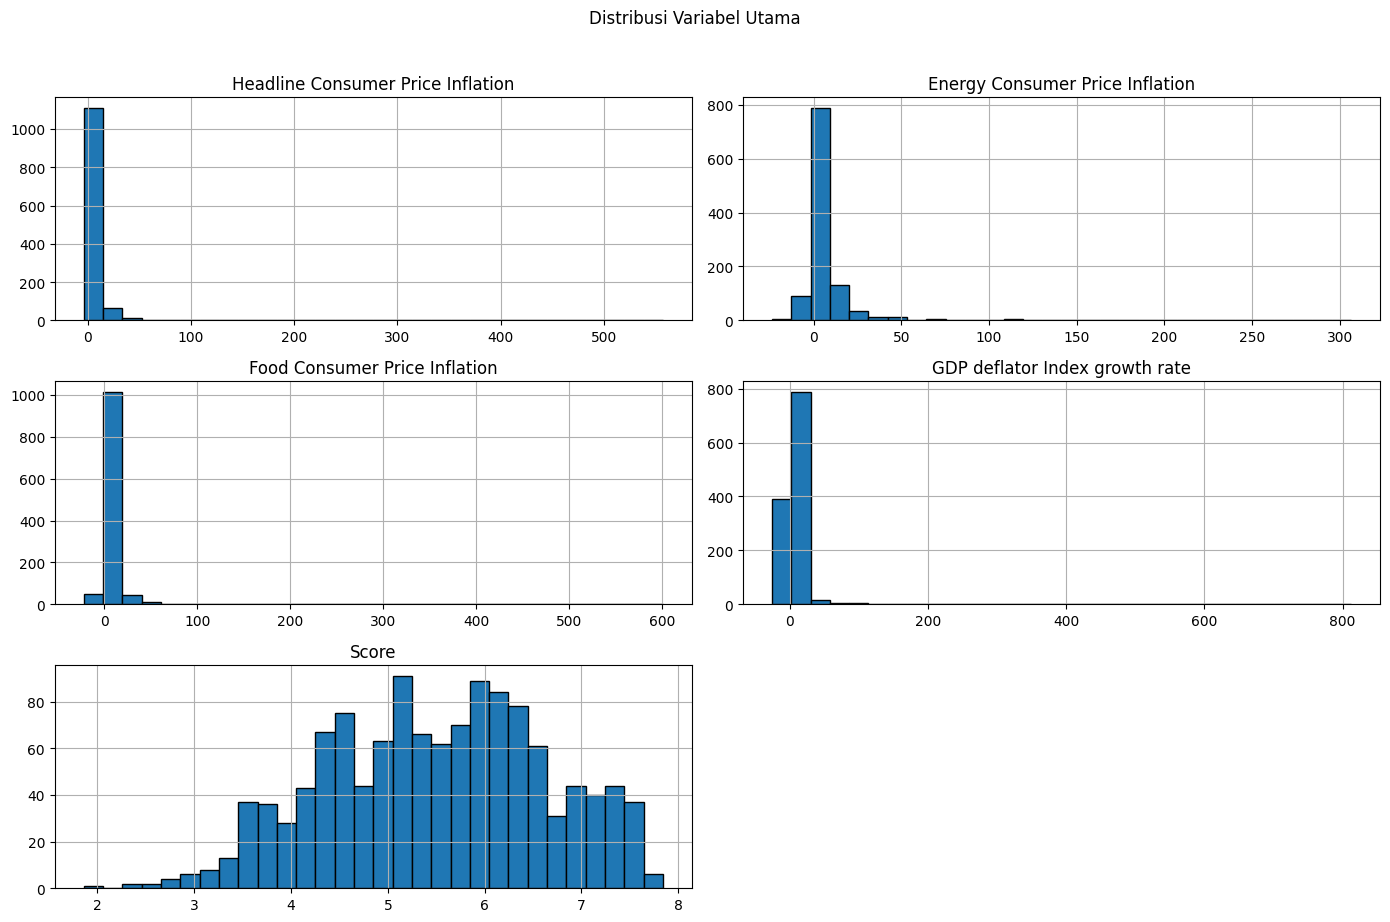

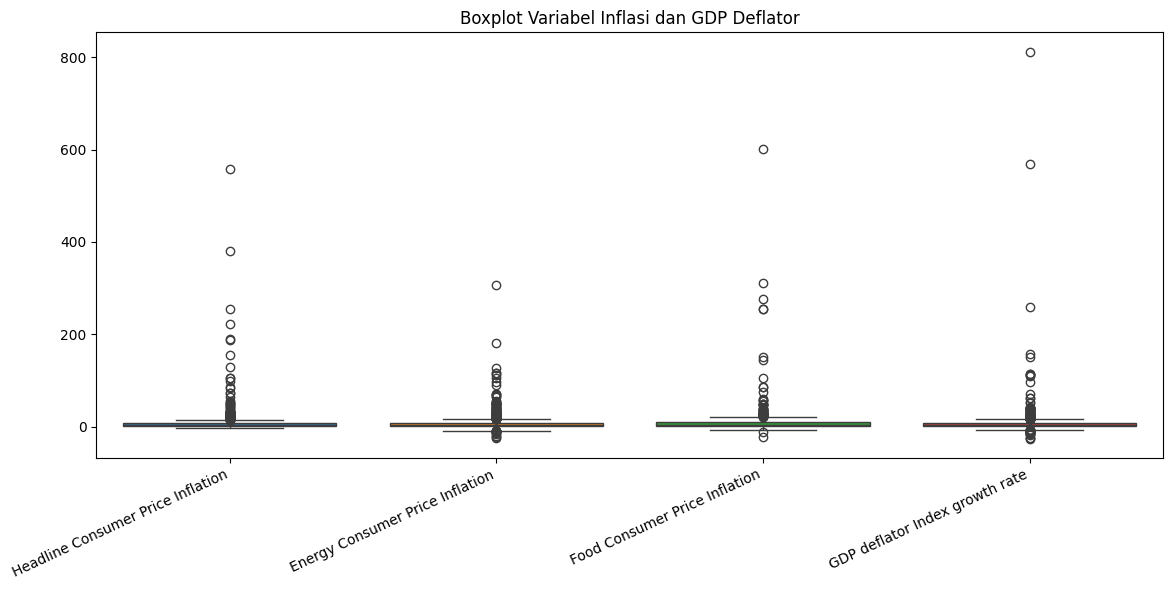

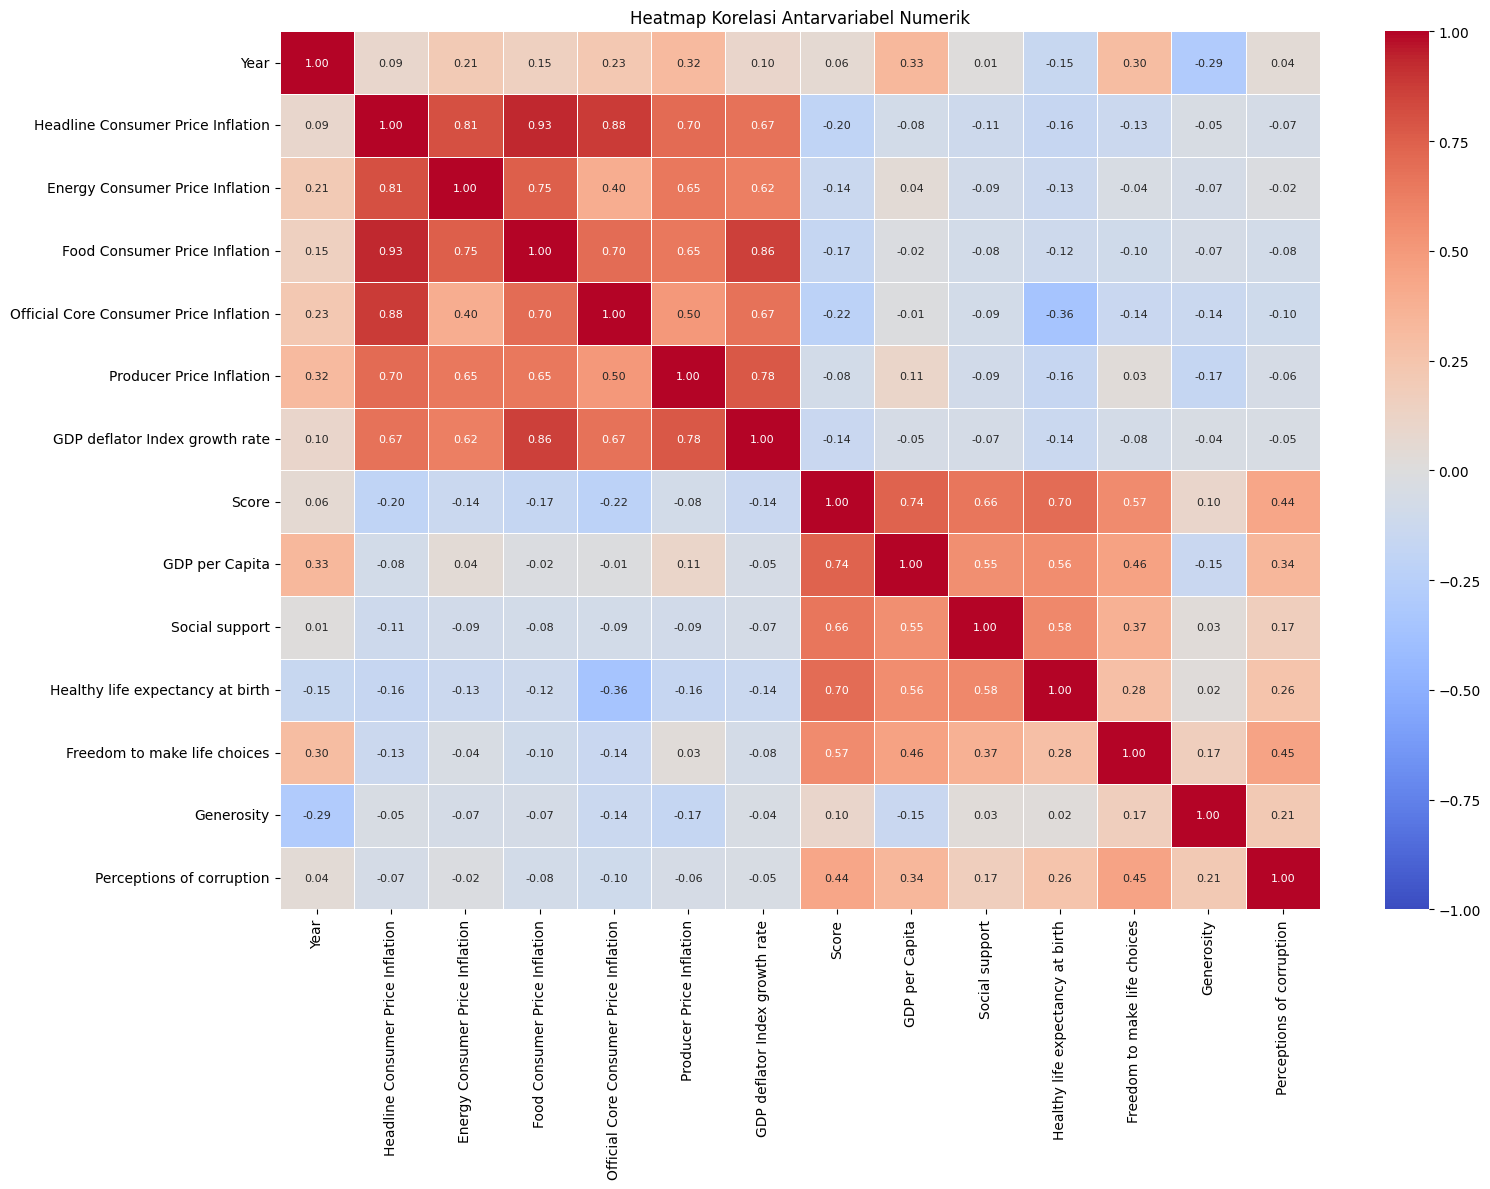

,Year,Rata_rata_Inflasi,Rata_rata_Skor,Jumlah_Observasi
0,2015,3.658330,5.434007,142
1,2016,7.089993,5.444929,141
2,2017,6.048674,5.408000,141
3,2018,5.023468,5.442303,142
4,2019,5.796763,5.481050,141
5,2020,8.578126,5.529455,138
6,2021,6.961386,5.581585,135
7,2022,13.046579,5.599977,130
8,2023,11.396343,5.595623,122


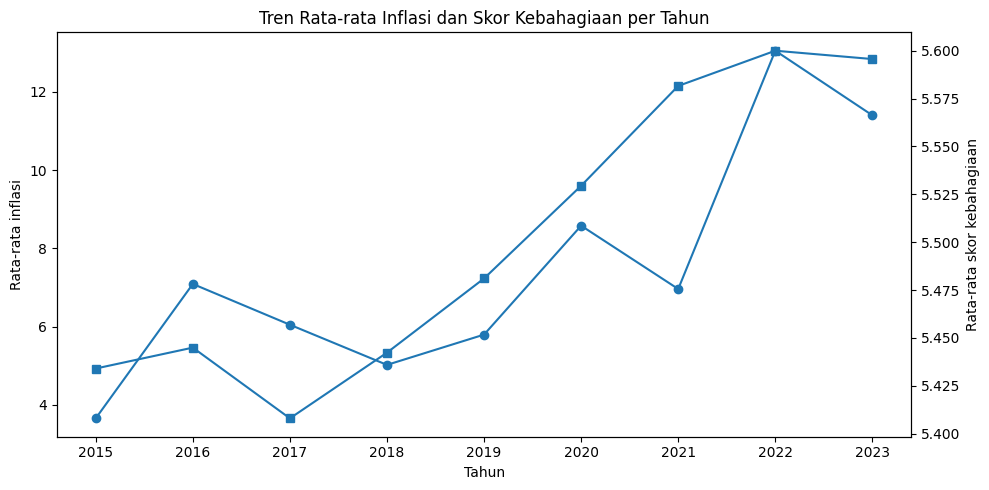

,Rata_rata_Inflasi,Rata_rata_Skor,Jumlah_Observasi,Jumlah_Negara
Continent/Region,,,,
Sub-Saharan Africa,13.164160,4.258036,306,39
Middle East and North Africa,9.574058,5.626581,120,15
Commonwealth of Independent States,9.166721,5.694637,35,4
Latin America and Caribbean,7.042402,6.028151,181,23
South Asia,6.612076,4.473264,61,8
Central and Eastern Europe,4.967790,5.568720,203,23
Southeast Asia,3.417831,5.420746,72,8
East Asia,3.181785,5.764481,36,4
North America and ANZ,2.713835,7.176058,36,4


In [12]:
kolom_utama = [
    "Headline Consumer Price Inflation",
    "Energy Consumer Price Inflation",
    "Food Consumer Price Inflation",
    "GDP deflator Index growth rate",
    "Score"
]

# Distribusi variabel utama
df[kolom_utama].hist(
    figsize=(14, 9),
    bins=30,
    edgecolor="black"
)
plt.suptitle("Distribusi Variabel Utama", y=1.02)
plt.tight_layout()
plt.show()

# Boxplot untuk melihat nilai ekstrem; nilai ekstrem tidak otomatis dihapus
kolom_inflasi = [
    "Headline Consumer Price Inflation",
    "Energy Consumer Price Inflation",
    "Food Consumer Price Inflation",
    "GDP deflator Index growth rate"
]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[kolom_inflasi])
plt.xticks(rotation=25, ha="right")
plt.title("Boxplot Variabel Inflasi dan GDP Deflator")
plt.tight_layout()
plt.show()

# Heatmap korelasi numerik dengan angka korelasi pada setiap kotak
kolom_numerik = df.select_dtypes(include=np.number).columns
matriks_korelasi = df[kolom_numerik].corr(numeric_only=True)

plt.figure(figsize=(16, 12))
sns.heatmap(
    matriks_korelasi,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    linewidths=0.4,
    vmin=-1,
    vmax=1
)
plt.title("Heatmap Korelasi Antarvariabel Numerik")
plt.tight_layout()
plt.show()

# Tren rata-rata tahunan; jumlah observasi per tahun juga ditampilkan
tren_tahunan = df.groupby("Year").agg(
    Rata_rata_Inflasi=("Headline Consumer Price Inflation", "mean"),
    Rata_rata_Skor=("Score", "mean"),
    Jumlah_Observasi=("Country", "count")
).reset_index()
display(tren_tahunan)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(
    tren_tahunan["Year"],
    tren_tahunan["Rata_rata_Inflasi"],
    marker="o",
    label="Rata-rata inflasi"
)
ax1.set_xlabel("Tahun")
ax1.set_ylabel("Rata-rata inflasi")

ax2 = ax1.twinx()
ax2.plot(
    tren_tahunan["Year"],
    tren_tahunan["Rata_rata_Skor"],
    marker="s",
    label="Rata-rata skor"
)
ax2.set_ylabel("Rata-rata skor kebahagiaan")

plt.title("Tren Rata-rata Inflasi dan Skor Kebahagiaan per Tahun")
fig.tight_layout()
plt.show()

# Ringkasan per wilayah
ringkasan_wilayah = df.groupby(
    "Continent/Region",
    dropna=False
).agg(
    Rata_rata_Inflasi=("Headline Consumer Price Inflation", "mean"),
    Rata_rata_Skor=("Score", "mean"),
    Jumlah_Observasi=("Country", "count"),
    Jumlah_Negara=("Country", "nunique")
).sort_values("Rata_rata_Inflasi", ascending=False)
display(ringkasan_wilayah)


### Interpretasi eksplorasi distribusi, korelasi, dan tren

- Histogram memperlihatkan bentuk distribusi dan kemencengan.
- Boxplot menandai nilai yang jauh dari mayoritas; nilai tersebut perlu ditelusuri, bukan langsung dihapus.
- Heatmap merangkum korelasi linear antarkolom numerik; korelasi bukan kausalitas.
- Tren tahunan merangkum rata-rata inflasi, rata-rata skor, dan jumlah observasi. Perubahan jumlah negara per tahun dapat memengaruhi perbandingan rata-rata.

# 3. Data Preparation

Pada tahap ini, data disiapkan secara transparan dan dapat dijalankan ulang. Strategi di bawah tidak mengubah `df` asli:
1. membuat salinan data;
2. memastikan kolom numerik benar-benar bertipe numerik;
3. memeriksa pasangan `Country-Year` berulang;
4. membuat dataset analisis dengan kolom yang dibutuhkan;
5. menghapus nilai kosong hanya untuk variabel yang dibutuhkan model tertentu, sambil melaporkan jumlah observasi yang tersisa.

**Kebijakan duplikasi:** jangan menghapus pasangan negara-tahun berulang secara otomatis sebelum penyebabnya diketahui. Jika memang duplikat akibat kesalahan penggabungan, tentukan aturan pemilihan satu baris berdasarkan sumber; jika observasinya berbeda secara sah, perlu klarifikasi data sumber.

**Kebijakan missing values:** analisis regresi sederhana memakai baris yang memiliki `Score` dan inflasi utama. Regresi berganda memakai baris lengkap untuk fitur yang dipilih. Ini adalah *complete-case analysis* dan dapat mengurangi ukuran sampel atau menimbulkan bias jika kehilangan data tidak acak. Imputasi tidak dilakukan otomatis karena perlu alasan substantif.

In [13]:
# Pipeline persiapan data yang dapat dijalankan ulang
df_prepared = df.copy()

kolom_numerik = [
    "Year", "Headline Consumer Price Inflation",
    "Energy Consumer Price Inflation", "Food Consumer Price Inflation",
    "Official Core Consumer Price Inflation", "Producer Price Inflation",
    "GDP deflator Index growth rate", "Score", "GDP per Capita",
    "Social support", "Healthy life expectancy at birth",
    "Freedom to make life choices", "Generosity", "Perceptions of corruption"
]
for kolom in kolom_numerik:
    if kolom in df_prepared.columns:
        df_prepared[kolom] = pd.to_numeric(df_prepared[kolom], errors="coerce")

print("Ukuran data awal:", df.shape)
print("Ukuran setelah pemeriksaan tipe numerik:", df_prepared.shape)
print("Jumlah baris identik:", df_prepared.duplicated().sum())
print("Jumlah pasangan Country-Year berulang:",
      df_prepared.duplicated(subset=["Country", "Year"], keep=False).sum())

duplikat_negara_tahun = df_prepared[
    df_prepared.duplicated(subset=["Country", "Year"], keep=False)
].sort_values(["Country", "Year"])
display(duplikat_negara_tahun)

# Dataset analisis utama: hanya variabel yang diperlukan dan tidak kosong
kolom_model_sederhana = [
    "Country", "Year", "Headline Consumer Price Inflation", "Score"
]
df_analisis = df_prepared[kolom_model_sederhana].dropna().copy()

print("Observasi lengkap untuk model sederhana:", len(df_analisis))
print("Negara yang terwakili:", df_analisis["Country"].nunique())
print("Rentang tahun:", df_analisis["Year"].min(), "-", df_analisis["Year"].max())

Ukuran data awal: (1232, 16)
Ukuran setelah pemeriksaan tipe numerik: (1232, 16)
Jumlah baris identik: 0
Jumlah pasangan Country-Year berulang: 4


,Country,Year,Headline Consumer Price Inflation,Energy Consumer Price Inflation,Food Consumer Price Inflation,Official Core Consumer Price Inflation,Producer Price Inflation,GDP deflator Index growth rate,Continent/Region,Score,GDP per Capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption
284,Cyprus,2018,1.430,7.8,0.726506,0.060417,2.327169,1.219101,Western Europe,5.835,1.229,1.211,0.909,0.495,0.179,0.154
285,Cyprus,2018,1.430,7.8,0.726506,0.060417,2.327169,1.219101,Western Europe,5.762,1.229,1.191,0.909,0.423,0.202,0.035
286,Cyprus,2019,0.556,-2.0,0.446110,0.633994,2.455504,0.883240,Western Europe,6.046,1.263,1.223,1.042,0.406,0.190,0.041
287,Cyprus,2019,0.556,-2.0,0.446110,0.633994,2.455504,0.883240,Western Europe,5.718,1.263,1.252,1.042,0.417,0.191,0.162


Observasi lengkap untuk model sederhana: 1200
Negara yang terwakili: 144
Rentang tahun: 2015 - 2023


## Penjelasan hasil Data Preparation
- `df_prepared` adalah salinan yang digunakan untuk persiapan; data asli `df` tetap tersedia.
- Konversi `to_numeric(..., errors="coerce")` membuat nilai yang tidak dapat dikonversi menjadi missing value agar bisa diaudit.
- Baris dengan nilai kosong pada fitur yang dibutuhkan tidak dipakai untuk model terkait, tetapi tidak berarti baris tersebut dihapus dari file asli.
- Jika ditemukan pasangan `Country-Year` berulang, periksa tabelnya dan dokumentasikan keputusan sebelum menghapus salah satu observasi.

# 4. Modeling

Model utama adalah **regresi linear sederhana**, dengan `Headline Consumer Price Inflation` sebagai prediktor (X) dan `Score` sebagai target (y). Model ini dipilih karena mudah dijelaskan: koefisien menunjukkan perubahan rata-rata skor yang diperkirakan terkait dengan kenaikan satu unit inflasi, dengan asumsi bentuk hubungan linear.

Pada notebook ini juga mencoba **regresi linear berganda** menggunakan beberapa indikator inflasi. Hasil kedua model tidak otomatis berarti model berganda lebih baik; bandingkan ukuran sampel, koefisien, asumsi, dan metrik validasinya. Baseline prediksi rata-rata digunakan sebagai pembanding minimum. Validasi pemisahan berdasarkan negara memberi gambaran tambahan tentang performa pada negara yang tidak dilihat saat pelatihan.

## Grafik Hubungan Inflasi dan Kebahagiaan

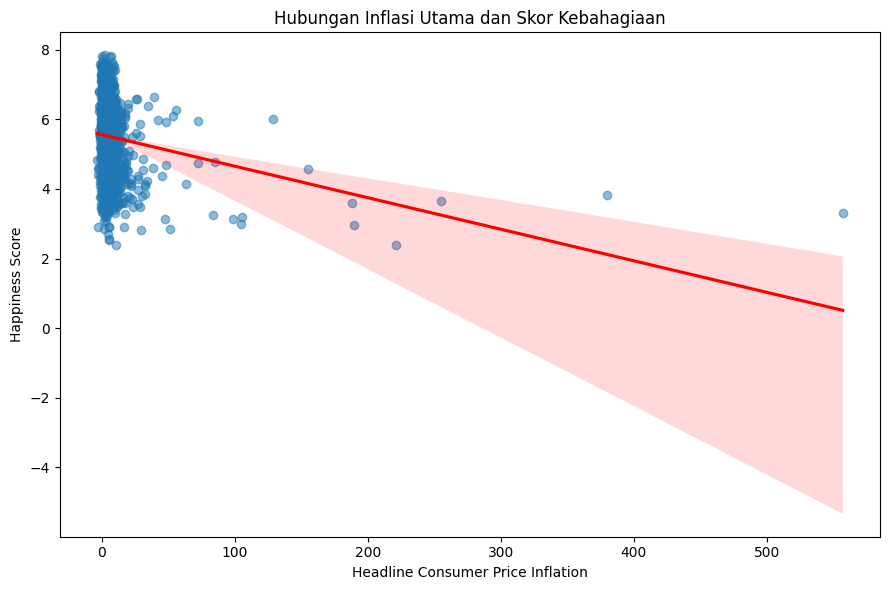

Jumlah observasi untuk analisis: 1200


In [14]:
kolom_x = "Headline Consumer Price Inflation"
kolom_y = "Score"

# Mengambil observasi yang memiliki kedua nilai
data_regresi = df[[kolom_x, kolom_y]].dropna()

plt.figure(figsize=(9, 6))

sns.regplot(
    data=data_regresi,
    x=kolom_x,
    y=kolom_y,
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Hubungan Inflasi Utama dan Skor Kebahagiaan")
plt.xlabel("Headline Consumer Price Inflation")
plt.ylabel("Happiness Score")
plt.tight_layout()
plt.show()

print("Jumlah observasi untuk analisis:", len(data_regresi))

### Interpretasi grafik hubungan

Setiap titik mewakili satu observasi negara–tahun. Garis regresi menunjukkan arah hubungan linear rata-rata. Sebaran titik yang lebar di sekitar garis berarti inflasi saja mungkin hanya menjelaskan sebagian kecil variasi skor. Nilai ekstrem dapat memengaruhi kemiringan garis, sehingga perlu dilihat bersama analisis sensitivitas.

## Menghitung Korelasi Awal

In [15]:
korelasi = data_regresi[kolom_x].corr(
    data_regresi[kolom_y]
)

print(f"Korelasi Pearson: {korelasi:.4f}")

Korelasi Pearson: -0.1999


### Interpretasi korelasi Pearson

Korelasi berada pada rentang −1 sampai +1. Nilai negatif menunjukkan kecenderungan skor lebih rendah ketika inflasi lebih tinggi; nilai yang mendekati 0 menunjukkan hubungan linear yang lemah. Korelasi tidak membuktikan sebab-akibat dan tidak menangkap semua kemungkinan hubungan non-linear.

## Membangun Regresi Linear

In [16]:
# Menentukan variabel X dan Y
X = data_regresi[[kolom_x]]
y = data_regresi[kolom_y]

# Membuat dan melatih model regresi linear
model = LinearRegression()
model.fit(X, y)

# Membuat prediksi pada data yang sama untuk pemeriksaan awal
y_pred = model.predict(X)

# Menampilkan persamaan regresi
print("INTERPRETASI MODEL REGRESI LINEAR")
print("-" * 40)
print(f"Intersep (b0): {model.intercept_:.4f}")
print(f"Koefisien inflasi (b1): {model.coef_[0]:.4f}")

print(
    f"\nPersamaan: Score = {model.intercept_:.4f} "
    f"+ ({model.coef_[0]:.4f} × Inflasi)"
)

# Evaluasi awal pada data yang sama
print("\nEvaluasi awal pada data pelatihan:")
print(f"R²   : {r2_score(y, y_pred):.4f}")
print(f"MAE  : {mean_absolute_error(y, y_pred):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y, y_pred)):.4f}")

INTERPRETASI MODEL REGRESI LINEAR
----------------------------------------
Intersep (b0): 5.5604
Koefisien inflasi (b1): -0.0091

Persamaan: Score = 5.5604 + (-0.0091 × Inflasi)

Evaluasi awal pada data pelatihan:
R²   : 0.0400
MAE  : 0.9323
RMSE : 1.1164


### Cara membaca persamaan regresi

- **Intersep** adalah prediksi skor ketika inflasi bernilai 0; interpretasinya perlu hati-hati jika nilai 0 tidak mewakili kondisi yang relevan.
- **Koefisien inflasi** menunjukkan perubahan rata-rata skor yang diperkirakan untuk kenaikan satu unit inflasi pada model sederhana.
- **R², MAE, dan RMSE pada data yang sama dengan pelatihan** hanya pemeriksaan awal; gunakan metrik data uji untuk menilai generalisasi.

## Evaluasi Menggunakan Data Latih dan Uji

In [17]:
# Membagi data menjadi 80% latih dan 20% uji
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Membuat model baru dan melatihnya hanya dengan data latih
model_uji = LinearRegression()
model_uji.fit(X_train, y_train)

# Prediksi pada data latih dan data uji
pred_train = model_uji.predict(X_train)
pred_test = model_uji.predict(X_test)

# Evaluasi pada data uji
print("JUMLAH DATA")
print("Data latih:", len(X_train))
print("Data uji:", len(X_test))

print("\nKOEFISIEN MODEL")
print("Intersep:", round(model_uji.intercept_, 4))
print("Koefisien inflasi:", round(model_uji.coef_[0], 4))

print("\nEVALUASI DATA UJI")
print("R²:", round(r2_score(y_test, pred_test), 4))
print("MAE:", round(mean_absolute_error(y_test, pred_test), 4))
print(
    "RMSE:",
    round(np.sqrt(mean_squared_error(y_test, pred_test)), 4)
)

JUMLAH DATA
Data latih: 960
Data uji: 240

KOEFISIEN MODEL
Intersep: 5.5456
Koefisien inflasi: -0.0084

EVALUASI DATA UJI
R²: 0.0344
MAE: 0.9044
RMSE: 1.079


## Menguji Signifikansi Hubungan

In [18]:
# Menggunakan data yang sama untuk analisis hubungan statistik
X_ols = sm.add_constant(X)

model_ols = sm.OLS(y, X_ols).fit()

print(model_ols.summary())

                            OLS Regression Results                            
Dep. Variable:                  Score   R-squared:                       0.040
Model:                            OLS   Adj. R-squared:                  0.039
Method:                 Least Squares   F-statistic:                     49.88
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           2.76e-12
Time:                        18:37:07   Log-Likelihood:                -1834.9
No. Observations:                1200   AIC:                             3674.
Df Residuals:                    1198   BIC:                             3684.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
const 

### Interpretasi hasil OLS

Lihat koefisien inflasi, interval kepercayaan, nilai-p, dan R². Nilai-p kecil menunjukkan bukti statistik terhadap hubungan linear dalam model dan asumsi yang digunakan, bukan bukti sebab-akibat. Periksa diagnostik residual dan gunakan standard error robust bila varians residual tidak konstan.

## Regresi Linear Berganda

In [19]:
fitur_inflasi = [
    "Headline Consumer Price Inflation",
    "Energy Consumer Price Inflation",
    "Food Consumer Price Inflation",
    "GDP deflator Index growth rate"
]

kolom_model = ["Country", "Year", "Score"] + fitur_inflasi

# Mengambil kolom yang diperlukan dan menghapus baris
# yang memiliki nilai kosong pada variabel model
data_berganda = df[kolom_model].dropna().copy()

X_multi = sm.add_constant(data_berganda[fitur_inflasi])
y_multi = data_berganda["Score"]

# Regresi linear berganda
model_multi = sm.OLS(y_multi, X_multi).fit(
    cov_type="cluster",
    cov_kwds={"groups": data_berganda["Country"]}
)

print(model_multi.summary())

print("\nJumlah observasi:", len(data_berganda))
print("Jumlah negara:", data_berganda["Country"].nunique())

                            OLS Regression Results                            
Dep. Variable:                  Score   R-squared:                       0.033
Model:                            OLS   Adj. R-squared:                  0.030
Method:                 Least Squares   F-statistic:                     6.878
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           4.61e-05
Time:                        18:37:07   Log-Likelihood:                -1647.5
No. Observations:                1078   AIC:                             3305.
Df Residuals:                    1073   BIC:                             3330.
Df Model:                           4                                         
Covariance Type:              cluster                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
const 

# 5. Evaluation

Evaluasi mencakup:
- **Metrik prediksi:** R², MAE, dan RMSE pada data uji, serta perbandingan dengan baseline.
- **Diagnostik residual:** pola residual, distribusi residual, dan pemeriksaan heteroskedastisitas.
- **Robustness/sensitivitas:** mengulang analisis tanpa observasi inflasi ekstrem untuk melihat apakah kesimpulan berubah.
- **Validasi kelompok:** memisahkan negara pelatihan dan pengujian agar tahun berbeda dari negara yang sama tidak tersebar ke kedua bagian.
- **Batas interpretasi:** nilai p dan interval/koefisien statistik tidak menghilangkan potensi bias, confounding, atau keterbatasan cakupan data.

## Membandingkan Model dengan Baseline

Pada evaluasi prediksi, regresi dibandingkan dengan baseline yang selalu memprediksi rata-rata `Score` dari data latih. Perbandingan ini membantu menilai apakah inflasi memberi manfaat prediktif dibanding tebakan sederhana.

In [20]:
# Evaluasi regresi sederhana dibanding baseline rata-rata data latih
X_baseline = data_regresi[[kolom_x]]
y_baseline = data_regresi[kolom_y]

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_baseline, y_baseline, test_size=0.20, random_state=42
)

model_baseline_regresi = LinearRegression()
model_baseline_regresi.fit(X_train_b, y_train_b)
pred_regresi = model_baseline_regresi.predict(X_test_b)

pred_baseline = np.repeat(y_train_b.mean(), len(y_test_b))

perbandingan_baseline = pd.DataFrame({
    "Model": ["Baseline rata-rata", "Regresi linear"],
    "R2": [
        r2_score(y_test_b, pred_baseline),
        r2_score(y_test_b, pred_regresi)
    ],
    "MAE": [
        mean_absolute_error(y_test_b, pred_baseline),
        mean_absolute_error(y_test_b, pred_regresi)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test_b, pred_baseline)),
        np.sqrt(mean_squared_error(y_test_b, pred_regresi))
    ]
})
display(perbandingan_baseline)


,Model,R2,MAE,RMSE
0,Baseline rata-rata,-0.003873,0.924315,1.100221
1,Regresi linear,0.034424,0.904415,1.079031


### Interpretasi perbandingan baseline

Baseline memprediksi rata-rata `Score` dari data latih untuk setiap observasi uji. Regresi lebih berguna untuk prediksi jika metrik uji membaik dibanding baseline, terutama MAE dan RMSE yang lebih rendah. Jika hasilnya mirip atau lebih buruk, kemampuan prediksi tambahan dari inflasi saja terbatas.

## Validasi dengan Pemisahan Berdasarkan Negara

Validasi kelompok memisahkan negara secara utuh ke data latih atau data uji. Tujuannya menguji apakah hubungan yang dipelajari dapat digeneralisasi ke negara yang tidak terlihat saat pelatihan. Ini bukan pengujian prediksi masa depan.

In [21]:
from sklearn.model_selection import GroupShuffleSplit

data_group = df_analisis[
    ["Country", "Headline Consumer Price Inflation", "Score"]
].dropna().copy()

X_group = data_group[["Headline Consumer Price Inflation"]]
y_group = data_group["Score"]
groups = data_group["Country"]

split_group = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
idx_train, idx_test = next(split_group.split(X_group, y_group, groups=groups))

X_train_group, X_test_group = X_group.iloc[idx_train], X_group.iloc[idx_test]
y_train_group, y_test_group = y_group.iloc[idx_train], y_group.iloc[idx_test]

model_group = LinearRegression()
model_group.fit(X_train_group, y_train_group)
pred_group = model_group.predict(X_test_group)

print("Jumlah observasi latih:", len(X_train_group))
print("Jumlah observasi uji:", len(X_test_group))
print("Jumlah negara latih:", groups.iloc[idx_train].nunique())
print("Jumlah negara uji:", groups.iloc[idx_test].nunique())
print("Irisan negara latih-uji:",
      len(set(groups.iloc[idx_train]) & set(groups.iloc[idx_test])))
print("\nEvaluasi pada negara yang tidak masuk data latih")
print("R²:", round(r2_score(y_test_group, pred_group), 4))
print("MAE:", round(mean_absolute_error(y_test_group, pred_group), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_group, pred_group)), 4))


Jumlah observasi latih: 948
Jumlah observasi uji: 252
Jumlah negara latih: 115
Jumlah negara uji: 29
Irisan negara latih-uji: 0

Evaluasi pada negara yang tidak masuk data latih
R²: -0.0208
MAE: 0.9785
RMSE: 1.1806


## Memeriksa Residual Regresi

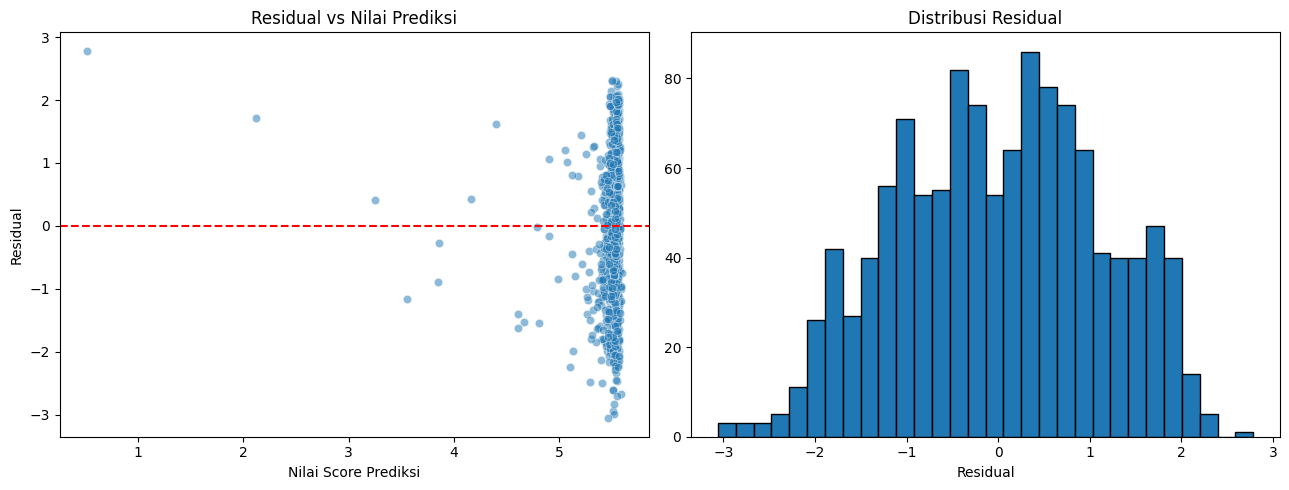

In [22]:
# Prediksi dan residual dari model OLS
prediksi_ols = model_ols.predict(X_ols)
residual = y - prediksi_ols

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafik residual terhadap nilai prediksi
sns.scatterplot(
    x=prediksi_ols,
    y=residual,
    alpha=0.5,
    ax=axes[0]
)
axes[0].axhline(0, linestyle="--", color="red")
axes[0].set_title("Residual vs Nilai Prediksi")
axes[0].set_xlabel("Nilai Score Prediksi")
axes[0].set_ylabel("Residual")

# Distribusi residual
axes[1].hist(residual, bins=30, edgecolor="black")
axes[1].set_title("Distribusi Residual")
axes[1].set_xlabel("Residual")

plt.tight_layout()
plt.show()

## Q-Q Plot Residual

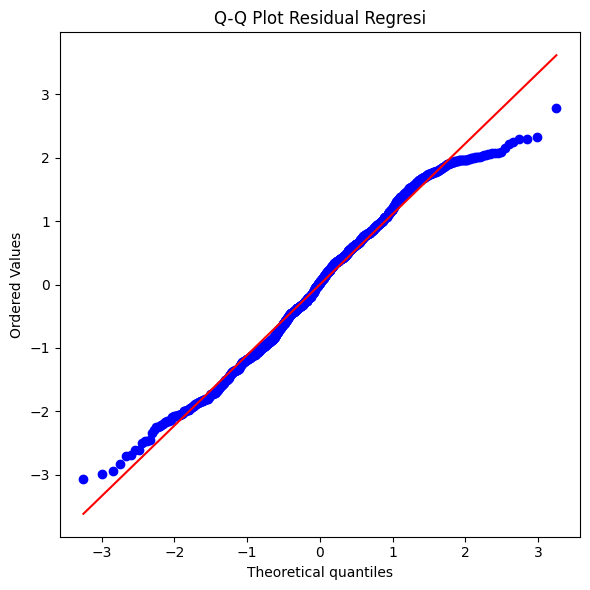

In [23]:
plt.figure(figsize=(6, 6))

stats.probplot(residual, dist="norm", plot=plt)

plt.title("Q-Q Plot Residual Regresi")
plt.tight_layout()
plt.show()

## Memeriksa Pola Residual dan Heteroskedastisitas

In [24]:
# Uji Breusch-Pagan untuk heteroskedastisitas
bp_test = het_breuschpagan(
    model_ols.resid,
    model_ols.model.exog
)

print("UJI BREUSCH-PAGAN")
print(f"LM Statistic : {bp_test[0]:.4f}")
print(f"LM p-value   : {bp_test[1]:.6f}")
print(f"F Statistic  : {bp_test[2]:.4f}")
print(f"F p-value    : {bp_test[3]:.6f}")

UJI BREUSCH-PAGAN
LM Statistic : 10.3736
LM p-value   : 0.001278
F Statistic  : 10.4466
F p-value    : 0.001262


### Interpretasi uji Breusch–Pagan

Hipotesis nol menyatakan varians residual konstan. Jika p-value di bawah ambang yang dipilih (sering 0,05), terdapat indikasi heteroskedastisitas. Dalam kondisi ini, standard error robust dapat membantu inferensi, tetapi tidak otomatis memperbaiki kemampuan prediksi model.

## Menggunakan Robust Standard Errors

In [25]:
# Menghitung OLS dengan robust standard errors HC3
model_ols_hc3 = model_ols.get_robustcov_results(
    cov_type="HC3"
)

print(model_ols_hc3.summary())

                            OLS Regression Results                            
Dep. Variable:                  Score   R-squared:                       0.040
Model:                            OLS   Adj. R-squared:                  0.039
Method:                 Least Squares   F-statistic:                     6.367
Date:                Fri, 30 Oct 2026   Prob (F-statistic):             0.0118
Time:                        18:37:08   Log-Likelihood:                -1834.9
No. Observations:                1200   AIC:                             3674.
Df Residuals:                    1198   BIC:                             3684.
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
const 

## Memeriksa Hasil Dipengaruhi Oleh Negara Tertentu

In [26]:
# Mengidentifikasi negara dengan inflasi utama tertinggi
negara_ekstrem = (
    df.loc[df["Headline Consumer Price Inflation"].idxmax(), "Country"]
)

print("Negara dengan inflasi tertinggi:", negara_ekstrem)

# Menyiapkan data lengkap untuk model awal
data_sensitivitas = df[
    ["Country", "Headline Consumer Price Inflation", "Score"]
].dropna()

# Model awal: semua negara
X_semua = sm.add_constant(
    data_sensitivitas[["Headline Consumer Price Inflation"]]
)
y_semua = data_sensitivitas["Score"]

hasil_semua = sm.OLS(y_semua, X_semua).fit().get_robustcov_results(
    cov_type="HC3"
)

# Model sensitivitas: mengecualikan sementara negara ekstrem
data_tanpa = data_sensitivitas[
    data_sensitivitas["Country"] != negara_ekstrem
]

X_tanpa = sm.add_constant(
    data_tanpa[["Headline Consumer Price Inflation"]]
)
y_tanpa = data_tanpa["Score"]

hasil_tanpa = sm.OLS(y_tanpa, X_tanpa).fit().get_robustcov_results(
    cov_type="HC3"
)

print("\nPERBANDINGAN ANALISIS SENSITIVITAS")
print(f"Semua negara: koefisien = {hasil_semua.params[1]:.5f}, "
      f"p-value = {hasil_semua.pvalues[1]:.5f}")

print(f"Tanpa {negara_ekstrem}: koefisien = {hasil_tanpa.params[1]:.5f}, "
      f"p-value = {hasil_tanpa.pvalues[1]:.5f}")    

Negara dengan inflasi tertinggi: Zimbabwe

PERBANDINGAN ANALISIS SENSITIVITAS
Semua negara: koefisien = -0.00906, p-value = 0.01176
Tanpa Zimbabwe: koefisien = -0.01238, p-value = 0.01331


## Pemeriksaan Multikolinearitas pada Regresi Berganda

Pada regresi berganda, beberapa indikator inflasi mungkin saling berkaitan. VIF digunakan sebagai alat diagnostik untuk menilai multikolinearitas. Nilai tinggi menjadi alasan untuk meninjau kombinasi fitur, bukan dasar otomatis untuk menghapus variabel.

VIF dihitung menggunakan prediktor yang sama dengan regresi linear berganda pada bagian Modeling. 
Karena `df_analisis` hanya disiapkan untuk regresi sederhana (satu prediktor), bagian ini menggunakan `data_berganda`, 
yang berisi empat indikator inflasi dan observasi lengkap untuk model berganda.

In [27]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Gunakan prediktor yang sama dengan model regresi linear berganda
fitur_inflasi_vif = [
    "Headline Consumer Price Inflation",
    "Energy Consumer Price Inflation",
    "Food Consumer Price Inflation",
    "GDP deflator Index growth rate"
]

# data_berganda dibuat pada bagian Regresi Linear Berganda
data_vif = data_berganda[fitur_inflasi_vif].dropna().copy()

if len(fitur_inflasi_vif) < 2:
    print("VIF tidak diperlukan karena model memiliki kurang dari dua prediktor.")
else:
    X_vif = sm.add_constant(data_vif)

    hasil_vif = pd.DataFrame({
        "Variabel": X_vif.columns,
        "VIF": [
            variance_inflation_factor(X_vif.values, i)
            for i in range(X_vif.shape[1])
        ]
    })

    display(hasil_vif)
    


,Variabel,VIF
0,const,1.000000
1,Headline Consumer Price Inflation,9.334614
2,Energy Consumer Price Inflation,2.731699
3,Food Consumer Price Inflation,7.624931
4,GDP deflator Index growth rate,4.873651


## Interpretasi, Risiko, dan Keterbatasan

Interpretasikan hasil dengan mempertimbangkan batasan berikut: korelasi/regresi menunjukkan hubungan statistik, bukan sebab-akibat; nilai ekstrem perlu diverifikasi dan diuji sensitivitasnya, bukan langsung dihapus; data kosong dapat membuat jumlah observasi berbeda antar-model; split acak dan split berdasarkan negara menjawab pertanyaan generalisasi yang berbeda; dan kesimpulan bergantung pada kualitas serta keterwakilan sumber data.

# 6. Deployment — Demo Notebook dan Rencana Penerapan

Bentuk deployment yang proporsional adalah fungsi demo yang menerima angka inflasi dan mengembalikan estimasi skor dari model regresi sederhana. Ini **bukan** alat penentu kebijakan atau prediksi resmi. Jangan gunakan di luar rentang data pelatihan tanpa peringatan.

Rencana operasional jika model dikembangkan lebih lanjut:
1. simpan versi dataset, kode, parameter, dan metrik evaluasi;
2. dokumentasikan skema input: inflasi utama dalam satuan yang sama dengan dataset;
3. validasi input kosong, teks, dan nilai di luar rentang;
4. pantau perubahan distribusi inflasi dan error prediksi ketika data baru tersedia (*data/concept drift*);
5. evaluasi ulang secara berkala dan latih ulang hanya setelah kualitas data dan performa diverifikasi.

In [28]:
# Demo prediksi sederhana untuk notebook
# Melatih model demo hanya dari observasi lengkap yang tersedia.
data_demo = df_prepared[
    ["Headline Consumer Price Inflation", "Score"]
].dropna().copy()

model_demo = LinearRegression()
model_demo.fit(
    data_demo[["Headline Consumer Price Inflation"]],
    data_demo["Score"]
)

rentang_inflasi = (
    data_demo["Headline Consumer Price Inflation"].min(),
    data_demo["Headline Consumer Price Inflation"].max()
)

def estimasi_score_dari_inflasi(nilai_inflasi):
    """Mengestimasi Score dari inflasi utama; hasil hanya untuk demo eksploratif."""
    nilai = float(nilai_inflasi)
    if not np.isfinite(nilai):
        raise ValueError("Nilai inflasi harus berupa angka yang valid.")
    peringatan = None
    if nilai < rentang_inflasi[0] or nilai > rentang_inflasi[1]:
        peringatan = (
            "Peringatan: nilai berada di luar rentang inflasi pada data; "
            "hasil merupakan ekstrapolasi dan kurang dapat diandalkan."
        )
    estimasi = float(model_demo.predict(pd.DataFrame({
        "Headline Consumer Price Inflation": [nilai]
    }))[0])
    return {"estimasi_score": estimasi, "peringatan": peringatan}

print("Rentang inflasi pada data:", rentang_inflasi)
print("Contoh demo:", estimasi_score_dari_inflasi(2.0))

Rentang inflasi pada data: (np.float64(-3.7529959678649902), np.float64(557.21))
Contoh demo: {'estimasi_score': 5.5422852800410345, 'peringatan': None}
